In [228]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
import textwrap
import duckdb

In [229]:
con = duckdb.connect()
con.read_parquet("../Data/Processed/orders_clean.parquet").create_view("orders");
con.read_parquet("../Data/Processed/customers_clean.parquet").create_view("customers");


### delivery duration analysis

In [230]:
delivery_time = con.sql(""" 
    select 
        order_id,
        order_purchase_timestamp,
        order_delivered_customer_date,
        delivery_duration_days
    from orders
    where order_status = 'delivered'
        and order_purchase_timestamp is not null
        and order_delivered_customer_date is not null
""").df()


In [231]:
print("orders with their delivery time:")
display(delivery_time.head(10))

orders with their delivery time:


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_duration_days
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-12-02 00:28:42,13.208750
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-16 18:17:02,2.873877
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-09 21:57:05,2017-07-26 10:57:55,16.542245
6,6514b8ad8028c9f2cc2374ded245783f,2017-05-16 13:10:30,2017-05-26 12:55:51,9.989826
7,76c6e866289321a7c93b82b54852dc33,2017-01-23 18:29:09,2017-02-02 14:08:10,9.818762
8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-07-29 11:55:02,2017-08-16 17:14:30,18.221852
9,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-16 19:41:10,2017-05-29 11:18:31,12.650937


In [232]:
#Statistical calculations
cal = delivery_time["delivery_duration_days"].describe().to_frame().round(1)
display(delivery_time["delivery_duration_days"].describe().to_frame().round(1))
print(f"longest delivery time : {cal.loc['max', 'delivery_duration_days']} days")
print(f"shortest delivery time : {cal.loc['min', 'delivery_duration_days']} days")
print(f"average delivery time : {cal.loc['mean', 'delivery_duration_days']} days")

,delivery_duration_days
count,96470.0
mean,12.6
std,9.5
min,0.5
25%,6.8
50%,10.2
75%,15.7
max,209.6


longest delivery time : 209.6 days
shortest delivery time : 0.5 days
average delivery time : 12.6 days


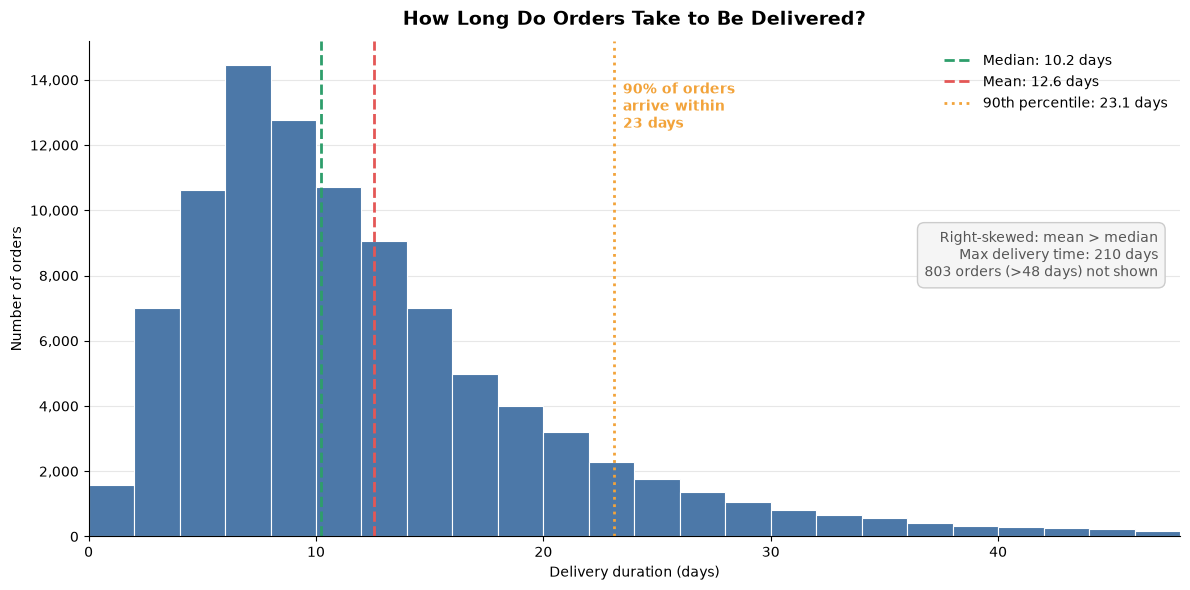

In [233]:
#delivery_time distribution chart
d = delivery_time["delivery_duration_days"]

mean, median = d.mean(), d.median()
p90, p95 = d.quantile(0.90), d.quantile(0.95)

# Zoom to the range that holds ~99% of orders; count the rest separately
cap = np.ceil(d.quantile(0.99) / 2) * 2   # round up to a multiple of the bin width
n_beyond = (d > cap).sum()

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    d[d <= cap],
    bins=np.arange(0, cap + 2, 2),   # 2-day wide bins
    color="#4C78A8",
    edgecolor="white",
    linewidth=0.8,
)

# Reference lines
ax.axvline(median, color="#2E9E6B", linestyle="--", linewidth=2, label=f"Median: {median:.1f} days")
ax.axvline(mean, color="#E45756", linestyle="--", linewidth=2, label=f"Mean: {mean:.1f} days")
ax.axvline(p90, color="#F2A33A", linestyle=":", linewidth=2, label=f"90th percentile: {p90:.1f} days")

# Note about the long right tail
ax.text(
    0.98, 0.62,
    f"Right-skewed: mean > median\n"
    f"Max delivery time: {d.max():.0f} days\n"
    f"{n_beyond:,} orders (>{cap:.0f} days) not shown",
    transform=ax.transAxes, ha="right", va="top", fontsize=10, color="#555555",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F5F5F5", edgecolor="#CCCCCC"),
)
ax.text(p90 + 0.4, ax.get_ylim()[1] * 0.92, "90% of orders\narrive within\n23 days",
        color="#F2A33A", fontsize=10, fontweight="bold", va="top")

ax.set_title("How Long Do Orders Take to Be Delivered?", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Delivery duration (days)")
ax.set_ylabel("Number of orders")
ax.set_xlim(0, cap)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
ax.legend(frameon=False, fontsize=10, loc="upper right")
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Business Conclusion – Delivery Duration Overview

The analysis of 96,470 successfully delivered orders reveals that the average delivery time is **12.6 days**, while the median delivery time is **10.2 days**. This difference suggests a positively skewed distribution, indicating that a number of orders with unusually long delivery durations increase the overall average.

The standard deviation of **9.5 days** also indicates considerable variability in delivery times, meaning that customers do not experience a consistent delivery duration.

The distribution analysis provides further insights:

- The middle 50% of orders(IQR) were delivered within **6.8 to 15.7 days**.
- **90% of orders** were delivered within approximately 23.1 days.(a useful “worst typical case” number and the 90th percentile is the better number for setting customer expectations)
- A relatively small proportion (about 1%) of orders experienced significantly longer delivery durations ( more than 48 days) with the maximum reaching approximately **210 days**.

The histogram confirms a right-skewed distribution, with most orders concentrated in shorter delivery intervals and a long tail representing delayed deliveries.

**Business Implications:**

Although the majority of customers receive their orders within a relatively reasonable time frame, the existence of extremely long delivery durations indicates potential operational issues affecting a smaller group of orders.

These extreme cases may negatively affect customer experience and should be investigated further.

However, this analysis alone does not identify the causes of long delivery times. Further investigation across different states and delivery periods is necessary to determine whether these delays are concentrated in specific regions or occur more broadly across the business.

**Overall, delivery performance appears reasonably concentrated for most orders, but significant variability and extreme delays remain important areas for operational improvement.**

### Delivery Delay Analysis

In [234]:
delay_days = con.sql(""" 
    select 
        order_id,
        order_delivered_customer_date,
        order_estimated_delivery_date,
        delivery_delay_days
    from orders
    where order_status = 'delivered'
        and order_estimated_delivery_date is not null
        and order_delivered_customer_date is not null
""").df()

#classify orders into early,on-time,late
conditions = [delay_days["delivery_delay_days"] < 0 ,
              delay_days["delivery_delay_days"] == 0 ,
              delay_days["delivery_delay_days"] > 0]

choices = ["early" , "on-time" , "late"]

delay_days["delay_status"] = np.select(conditions ,choices ,default="unknown")

display(delay_days.head(10))

,order_id,order_delivered_customer_date,order_estimated_delivery_date,delivery_delay_days,delay_status
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-10 21:25:13,2017-10-18,-8,early
1,53cdb2fc8bc7dce0b6741e2150273451,2018-08-07 15:27:45,2018-08-13,-6,early
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-17 18:06:29,2018-09-04,-18,early
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-12-02 00:28:42,2017-12-15,-13,early
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-16 18:17:02,2018-02-26,-10,early
5,a4591c265e18cb1dcee52889e2d8acc3,2017-07-26 10:57:55,2017-08-01,-6,early
6,6514b8ad8028c9f2cc2374ded245783f,2017-05-26 12:55:51,2017-06-07,-12,early
7,76c6e866289321a7c93b82b54852dc33,2017-02-02 14:08:10,2017-03-06,-32,early
8,e69bfb5eb88e0ed6a785585b27e16dbf,2017-08-16 17:14:30,2017-08-23,-7,early
9,e6ce16cb79ec1d90b1da9085a6118aeb,2017-05-29 11:18:31,2017-06-07,-9,early


In [235]:
total = delay_days["delay_status"].count()

early   = (delay_days["delay_status"] == "early").sum()
on_time = (delay_days["delay_status"] == "on-time").sum()
late    = (delay_days["delay_status"] == "late").sum()

print(f"number of orders delivered early   : {early}")
print(f"number of orders delivered on-time : {on_time}")
print(f"number of orders delivered late    : {late}")

print(f"\norders delivered early   share : {early   / total * 100:.2f}%")
print(f"orders delivered on-time share : {on_time / total * 100:.2f}%")
print(f"orders delivered late    share : {late    / total * 100:.2f}%")

number of orders delivered early   : 88644
number of orders delivered on-time : 1292
number of orders delivered late    : 6534

orders delivered early   share : 91.89%
orders delivered on-time share : 1.34%
orders delivered late    share : 6.77%


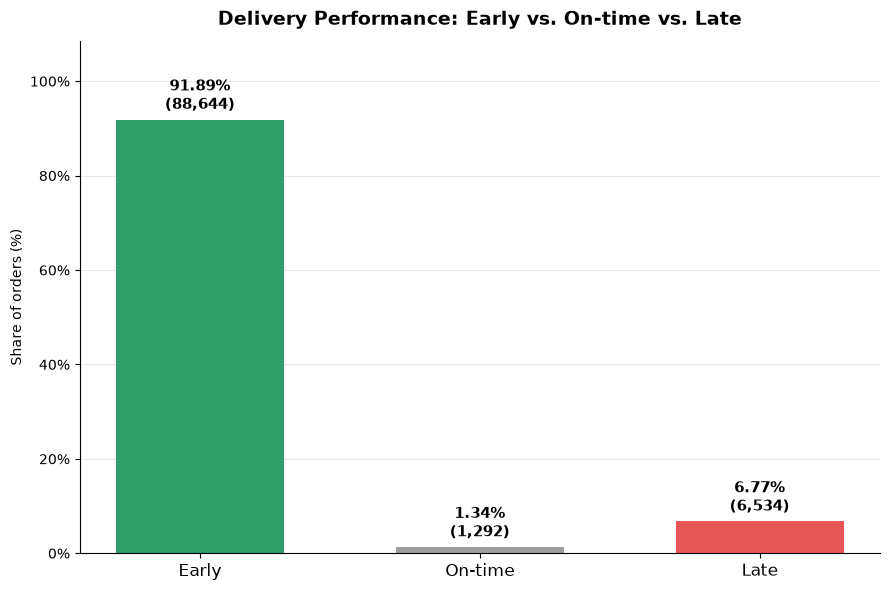

In [236]:

# Count orders in each delivery status
status_counts = (
    delay_days["delay_status"]
    .value_counts()
    .reindex(["early", "on-time", "late"], fill_value=0)
)

total_orders = status_counts.sum()
status_percentages = status_counts / total_orders * 100

# Semantic colors: green = early, gray = on-time, red = late
color_map = {"early": "#2E9E6B", "on-time": "#9E9E9E", "late": "#E45756"}
colors = [color_map[s] for s in status_counts.index]

fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    status_counts.index.str.capitalize(),
    status_percentages.values,
    color=colors,
    width=0.6,
)

# Percentage and count above each bar
ax.bar_label(
    bars,
    labels=[f"{p:.2f}%\n({c:,})" for p, c in zip(status_percentages.values, status_counts.values)],
    padding=4,
    fontsize=11,
    fontweight="bold",
)

ax.set_title("Delivery Performance: Early vs. On-time vs. Late", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Share of orders (%)")
ax.set_ylim(0, status_percentages.max() * 1.18)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [237]:
#investigate in late delivery
#Group late orders into the days ranges

late = delay_days[delay_days["delay_status"] == "late"]

conditions = [late["delivery_delay_days"].between(1,3) ,
              late["delivery_delay_days"].between(4,7) ,
              late["delivery_delay_days"] > 7] 

choices = ["1-3 days", "4-7 days", "More than 7 days"]

late["delay_group"] = np.select(conditions,choices,default="unknown")


print(f"average and median delay days for late orders: {late["delivery_delay_days"].mean():.1f} days(average) and {late["delivery_delay_days"].median()} days(median)")

for group in choices:
    n = (late["delay_group"] == group).sum()
    print(f"orders late by {group:<18}: {n:>6}  ({n / len(late) * 100:.2f}%)")

average and median delay days for late orders: 10.6 days(average) and 7.0 days(median)
orders late by 1-3 days          :   1870  (28.62%)
orders late by 4-7 days          :   1802  (27.58%)
orders late by More than 7 days  :   2862  (43.80%)


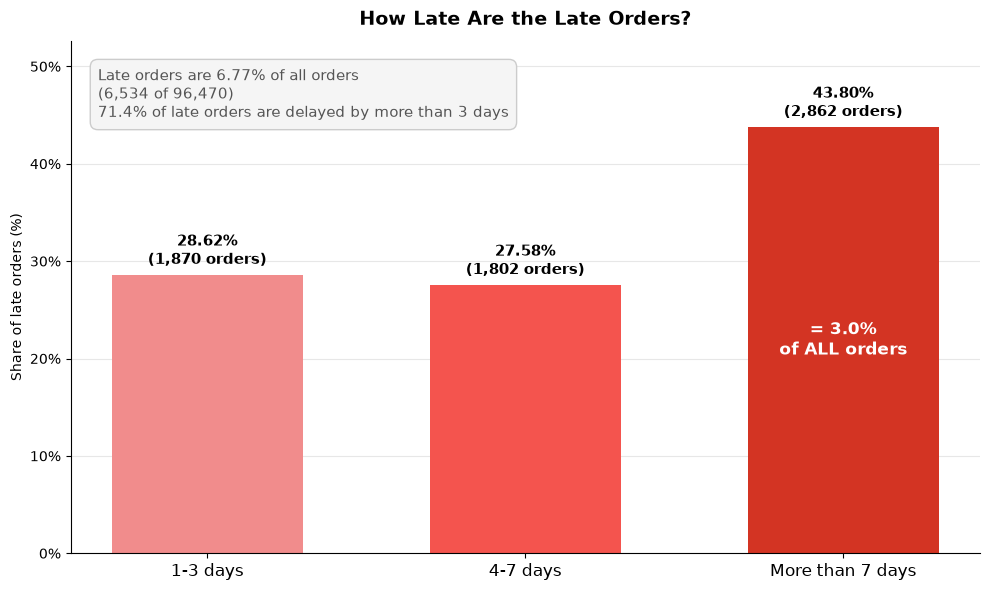

In [238]:

group_order = ["1-3 days", "4-7 days", "More than 7 days"]

group_counts = (
    late["delay_group"]
    .value_counts()
    .reindex(group_order, fill_value=0)
)
group_percentages = group_counts / group_counts.sum() * 100

# Context numbers: late orders relative to ALL orders
total_orders = len(delay_days)               # all orders (early + on-time + late); adjust if your variable differs
late_total = group_counts.sum()
late_of_all = late_total / total_orders * 100
severe_count = group_counts["More than 7 days"]
severe_of_all = severe_count / total_orders * 100
over_3 = group_percentages[["4-7 days", "More than 7 days"]].sum()

colors = ["#F18C8C", "#F4544E", "#D33423"]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(group_order, group_percentages.values, color=colors, width=0.6)

ax.bar_label(
    bars,
    labels=[f"{p:.2f}%\n({c:,} orders)" for p, c in zip(group_percentages.values, group_counts.values)],
    padding=4,
    fontsize=11,
    fontweight="bold",
)

# Inside the worst bar: its share of ALL orders
worst = bars[2]
ax.text(
    worst.get_x() + worst.get_width() / 2,
    worst.get_height() / 2,
    f"= {severe_of_all:.1f}%\nof ALL orders",
    ha="center", va="center", fontsize=12, fontweight="bold", color="white",
)

# Callout with the key context
ax.text(
    0.03, 0.95,
    f"Late orders are {late_of_all:.2f}% of all orders\n"
    f"({late_total:,} of {total_orders:,})\n"
    f"{over_3:.1f}% of late orders are delayed by more than 3 days",
    transform=ax.transAxes, ha="left", va="top", fontsize=11, color="#555555",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="#F5F5F5", edgecolor="#CCCCCC"),
)

ax.set_title("How Late Are the Late Orders?", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Share of late orders (%)")
ax.set_ylim(0, group_percentages.max() * 1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x)}%"))
ax.tick_params(axis="x", labelsize=12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

#### Business Conclusion – Delivery Delays and Delivery Performance

The analysis of 96,470 delivered orders reveals that Olist performs relatively well in meeting or exceeding its estimated delivery dates.

- **91.89%** of orders (88,644 orders) were delivered earlier than estimated.
- **1.34%** (1,292 orders) were delivered exactly on the estimated date.
- **6.77%** (6,534 orders) were delivered later than expected.

Although the overall late delivery rate is relatively low, further investigation reveals that a considerable proportion of late orders experience significant delays.

Among the 6,534 late orders:

- 28.62% were delayed by 1–3 days.
- 27.58% were delayed by 4–7 days.
- 43.80% were delayed by more than 7 days.

The average delay among late orders is **10.6 days**, while the median is **7 days**, suggesting that some orders experience considerably longer delays and increase the average.The 7-day median provides a better picture of the midpoint of this statistical population.

**Business Implications:**

Despite the high proportion of early deliveries, the number and severity of late deliveries remain important operational concerns.

In particular, the 2,862 orders delayed by more than seven days represent approximately **2.97% of all delivered orders** and deserve further investigation.

Olist should focus on identifying the operational factors associated with these significant delays rather than evaluating delivery performance solely through the overall late delivery rate.

Additionally, the very high percentage of early deliveries may indicate that estimated delivery dates are relatively conservative. Reviewing the accuracy of delivery time estimates could help improve delivery planning and provide customers with more reliable expectations.

**Overall, Olist delivers most orders earlier than estimated, but a smaller group of customers experiences substantial delivery delays. Reducing these severe delays and improving delivery time estimation should be important priorities for operational improvement.**

### Geographic Delivery Analysis

In [239]:
geographic_delivery = con.sql(""" 
    select 
        c.customer_state,
        round(avg(o.delivery_duration_days),1) as avg_delivery_time_days,
        count(o.order_id) as orders_count,
        round(sum(o.is_late) * 100 / count(*),2) as late_rate_pct
    from orders as o
    left join customers as c
        on c.customer_id = o.customer_id
    where o.order_status = 'delivered'
            and o.order_purchase_timestamp is not null
            and o.order_delivered_customer_date is not null
    group by c.customer_state
    order by avg_delivery_time_days desc
""").df()

geographic_delivery["late_orders"] = (geographic_delivery["orders_count"] * geographic_delivery["late_rate_pct"] / 100).round()

In [240]:
print("States with the Longest Average Delivery Time to shortest:")
display(geographic_delivery)

States with the Longest Average Delivery Time to shortest:


,customer_state,avg_delivery_time_days,orders_count,late_rate_pct,late_orders
0,RR,29.4,41,12.20,5.0
1,AP,27.2,67,2.99,2.0
2,AM,26.4,145,2.76,4.0
3,AL,24.5,397,21.41,85.0
4,PA,23.8,946,11.21,106.0
5,MA,21.6,717,17.43,125.0
6,SE,21.5,335,15.22,51.0
7,CE,21.3,1279,13.76,176.0
8,AC,21.0,80,3.75,3.0
9,PB,20.4,517,10.44,54.0


In [241]:
#calculate weighted mean 
weighted_avg_delivery = (
    (geographic_delivery["avg_delivery_time_days"] * geographic_delivery["orders_count"]).sum()
    / geographic_delivery["orders_count"].sum()
)

weighted_late_rate = (
    (geographic_delivery["late_rate_pct"] * geographic_delivery["orders_count"]).sum()
    / geographic_delivery["orders_count"].sum()
)


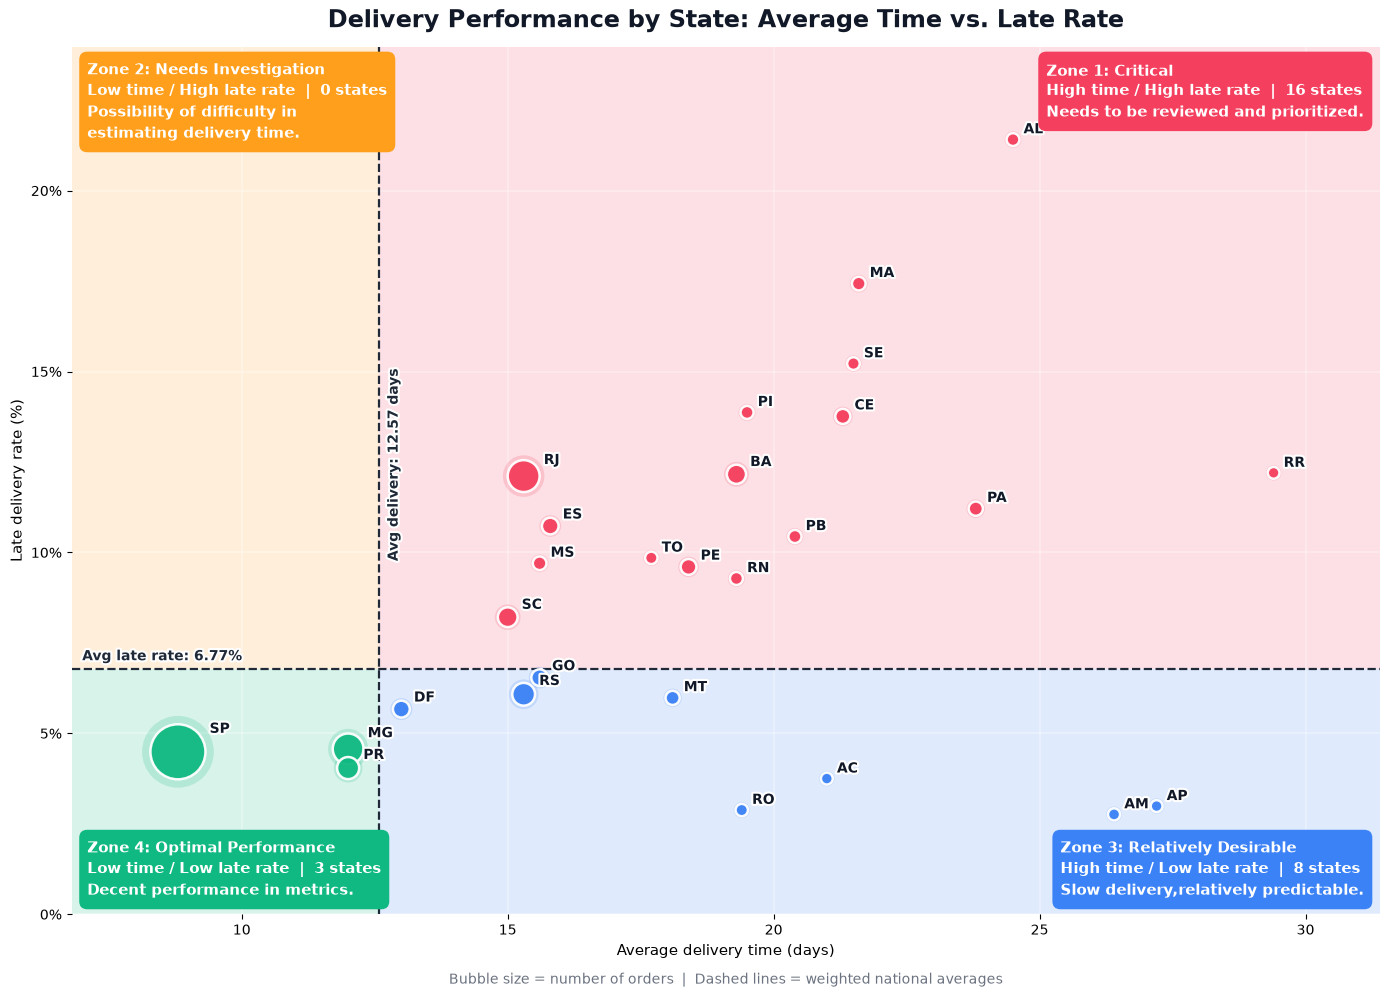

In [242]:
#Scatter plot: Average delivery time vs. late delivery rate by state
df = geographic_delivery.copy()
x = df["avg_delivery_time_days"]
y = df["late_rate_pct"]
vx, vy = weighted_avg_delivery, weighted_late_rate

def quadrant(xv, yv):
    if xv > vx and yv > vy:   return "Critical"
    if xv <= vx and yv > vy:  return "Needs Investigation"
    if xv > vx and yv <= vy:  return "Relatively Desirable"
    return "Optimal Performance"

df["zone"] = [quadrant(a, b) for a, b in zip(x, y)]

zone_style = {
    "Critical": {
        "color": "#F43F5E", "title": "Zone 1: Critical",
        "sub": "High time / High late rate",
        "note": "Needs to be reviewed and prioritized.", "wrap": 40,
    },
    "Needs Investigation": {
        "color": "#FF9F1C", "title": "Zone 2: Needs Investigation",
        "sub": "Low time / High late rate",
        "note": "Possibility of difficulty in estimating delivery time.", "wrap": 30,
    },
    "Relatively Desirable": {
        "color": "#3B82F6", "title": "Zone 3: Relatively Desirable",
        "sub": "High time / Low late rate",
        "note": "Slow delivery,relatively predictable.", "wrap": 40,
    },
    "Optimal Performance": {
        "color": "#10B981", "title": "Zone 4: Optimal Performance",
        "sub": "Low time / Low late rate",
        "note": "Decent performance in metrics.", "wrap": 30,
    },
}

x_min, x_max = x.min() - 2, x.max() + 2
y_min, y_max = 0, y.max() * 1.12

fig, ax = plt.subplots(figsize=(14, 10))
fig.patch.set_facecolor("white")

# Shaded quadrants
quads = [
    ((x_min, vy),    vx - x_min, y_max - vy, "Needs Investigation"),
    ((vx, vy),       x_max - vx, y_max - vy, "Critical"),
    ((x_min, y_min), vx - x_min, vy - y_min, "Optimal Performance"),
    ((vx, y_min),    x_max - vx, vy - y_min, "Relatively Desirable"),
]
for xy, w, h, z in quads:
    ax.add_patch(Rectangle(xy, w, h, facecolor=zone_style[z]["color"], alpha=0.16, edgecolor="none", zorder=0))

# Average lines
ax.axvline(vx, color="#1F2937", linestyle="--", linewidth=1.6, zorder=1)
ax.axhline(vy, color="#1F2937", linestyle="--", linewidth=1.6, zorder=1)

# Bubbles with a soft glow ring
sizes = 70 + df["orders_count"] / df["orders_count"].max() * 1500
point_colors = df["zone"].map(lambda z: zone_style[z]["color"])
ax.scatter(x, y, s=sizes * 1.7, c=point_colors, alpha=0.18, edgecolor="none", zorder=2)
ax.scatter(x, y, s=sizes, c=point_colors, alpha=0.95, edgecolor="white", linewidth=1.8, zorder=3)

# State labels with white halo
halo = [pe.withStroke(linewidth=3, foreground="white")]
for (_, r), s in zip(df.iterrows(), sizes):
    offset = np.sqrt(s) / 2 + 3
    ax.annotate(
        r["customer_state"],
        (r["avg_delivery_time_days"], r["late_rate_pct"]),
        xytext=(offset, offset * 0.6), textcoords="offset points",
        fontsize=10, fontweight="bold", color="#111827", zorder=5, path_effects=halo,
    )

# Zone boxes: title + description + count + explanation
counts = df["zone"].value_counts()
corner = {
    "Needs Investigation":  (0.012, 0.985, "left",  "top"),
    "Critical":             (0.988, 0.985, "right", "top"),
    "Optimal Performance":  (0.012, 0.015, "left",  "bottom"),
    "Relatively Desirable": (0.988, 0.015, "right", "bottom"),
}
for z, (tx, ty, ha, va) in corner.items():
    st = zone_style[z]
    n = counts.get(z, 0)
    note = textwrap.fill(st["note"], width=st["wrap"])
    text = f"{st['title']}\n{st['sub']}  |  {n} state{'s' if n != 1 else ''}\n{note}"
    ax.text(
        tx, ty, text,
        transform=ax.transAxes, ha=ha, va=va, fontsize=10.5, fontweight="bold",
        color="white", linespacing=1.45, zorder=6, multialignment="left",
        bbox=dict(boxstyle="round,pad=0.55", facecolor=st["color"], edgecolor="none"),
    )

# Labels for the average lines
ax.text(vx + 0.15, y_max * 0.52, f"Avg delivery: {vx:.2f} days", rotation=90,
        va="center", ha="left", fontsize=10, fontweight="bold", color="#1F2937", path_effects=halo)
ax.text(x_min + 0.2, vy + 0.25, f"Avg late rate: {vy:.2f}%",
        fontsize=10, fontweight="bold", color="#1F2937", path_effects=halo)

ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.set_title("Delivery Performance by State: Average Time vs. Late Rate",
             fontsize=17, fontweight="bold", color="#111827", pad=14)
ax.set_xlabel("Average delivery time (days)", fontsize=11)
ax.set_ylabel("Late delivery rate (%)", fontsize=11)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0f}%"))
ax.grid(alpha=0.35, color="white", linewidth=1.2)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)

ax.text(0.5, -0.08, "Bubble size = number of orders  |  Dashed lines = weighted national averages",
        transform=ax.transAxes, ha="center", fontsize=10, color="#6B7280")

plt.tight_layout()
plt.show()

In [243]:
# states with delivery_time and late_rate more than their weighted mean
zone1 = geographic_delivery[
    (geographic_delivery["late_rate_pct"] > weighted_late_rate) &
    (geographic_delivery["avg_delivery_time_days"] > weighted_avg_delivery)
]

print(" regions with both high average delivery time and high late delivery rates: (zone 1)")
display(zone1)

 regions with both high average delivery time and high late delivery rates: (zone 1)


,customer_state,avg_delivery_time_days,orders_count,late_rate_pct,late_orders
0,RR,29.4,41,12.20,5.0
3,AL,24.5,397,21.41,85.0
4,PA,23.8,946,11.21,106.0
5,MA,21.6,717,17.43,125.0
6,SE,21.5,335,15.22,51.0
7,CE,21.3,1279,13.76,176.0
9,PB,20.4,517,10.44,54.0
10,PI,19.5,476,13.87,66.0
12,BA,19.3,3256,12.16,396.0
13,RN,19.3,474,9.28,44.0


#### Business Conclusion – Delivery Performance by State

The analysis reveals significant differences in delivery performance across Brazilian states. The weighted national average delivery time is **12.57 days**, while the overall late delivery rate is approximately **6.77%**. The results indicate that delivery challenges are not distributed equally across regions.

Several states show both higher-than-average delivery times and late delivery rates, making them the primary areas of concern. Among these states:

- **AL (Alagoas)** has the highest late delivery rate at **21.41%**, alongside an average delivery time of 24.5 days.
- **MA (Maranhão)** and **SE (Sergipe)** also show particularly high late delivery rates of 17.43% and 15.22%, respectively.
- **CE (Ceará)** is another important concern, with 1,279 orders, an average delivery time of 21.3 days, and a late rate of 13.76%.
- **BA (Bahia)** deserves special attention because of its substantial order volume (3,256 orders) combined with a 12.16% late delivery rate.

In terms of absolute numbers, **RJ (Rio de Janeiro)** has the highest number of late orders (1,496), followed by **SP (São Paulo)** with 1,818 late orders. However, SP's late rate is only 4.49%, illustrating why absolute late-order counts should not be confused with delivery performance. High-volume states can have many late orders even when their late delivery rates are relatively low.

On the other hand, **SP, MG, and PR** demonstrate relatively strong delivery performance, with shorter average delivery times and below-average late delivery rates. These states can serve as useful benchmarks for identifying potentially effective logistics practices.

The scatter plot also highlights an important distinction between slow delivery and unreliable delivery. For example, **AP and AM** have relatively long delivery times but low late delivery rates. This suggests that their estimated delivery dates may account for longer transportation times, even though their deliveries are generally predictable.

**Business Recommendations:**

1. Prioritize logistics investigation in AL, MA, SE, CE, and BA, where both delivery time and late delivery rates are relatively high.
2. Pay particular attention to BA and CE because their combination of high late rates and substantial order volumes makes their operational problems more significant.
3. Investigate RJ separately because of its large absolute number of late orders, despite having a delivery time closer to the national average.
4. Examine the logistics practices and delivery processes in SP, MG, and PR to identify approaches that could potentially be applied to underperforming regions.
5. Review delivery-time estimation methods in states such as AP and AM, where deliveries take longer but are usually completed within the promised timeframe.

**Overall, Olist should focus not only on reducing average delivery time but also on improving delivery reliability.** Regional logistics optimization, better delivery-time estimation, and targeted investigation of high-risk states could help reduce late deliveries and improve customer satisfaction.

### Delivery Performance Over Time

In [244]:
delivery_monthly = con.sql(""" 
    select
        order_year,
        order_month,
        count(order_id) as orders_count,
        round(avg(delivery_duration_days),1) as avg_delivery_time_days,
        round(sum(is_late) * 100 / count(*),2) as late_rate_pct
    from orders
    where order_status = 'delivered'
        and order_purchase_timestamp is not null
        and order_delivered_customer_date is not null
        and delivery_delay_days is not null
    group by order_year , order_month
    order by order_year, order_month
""").df()

#a real date column (first day of the month), so months sort and plot in order
delivery_monthly["month_start"] = pd.to_datetime(dict(year=delivery_monthly["order_year"],
                                                   month=delivery_monthly["order_month"], day=1))
#month name
delivery_monthly["month_abbr"] = delivery_monthly["month_start"].dt.strftime("%b")   #Jan, Feb, ...

delivery_monthly["late_orders"] = (delivery_monthly["orders_count"] * delivery_monthly["late_rate_pct"] / 100).round()

#valid analysis window (months before/after it have incomplete data, see below)
START = pd.Timestamp("2017-01-01")
END   = pd.Timestamp("2018-08-01")   #last valid month (month-start date)

delivery_monthly = delivery_monthly.set_index("month_start")
delivery_monthly = delivery_monthly[START:END]
delivery_monthly = delivery_monthly[["month_abbr","orders_count","avg_delivery_time_days","late_rate_pct","late_orders"]]

delivery_monthly

,month_abbr,orders_count,avg_delivery_time_days,late_rate_pct,late_orders
month_start,,,,,
2017-01-01,Jan,750,12.6,2.93,22.0
2017-02-01,Feb,1653,13.2,2.96,49.0
2017-03-01,Mar,2546,13.0,4.56,116.0
2017-04-01,Apr,2303,14.9,6.56,151.0
2017-05-01,May,3545,11.3,2.99,106.0
2017-06-01,Jun,3135,12.0,3.03,95.0
2017-07-01,Jul,3872,11.6,2.79,108.0
2017-08-01,Aug,4193,11.1,2.91,122.0
2017-09-01,Sep,4150,11.9,4.39,182.0


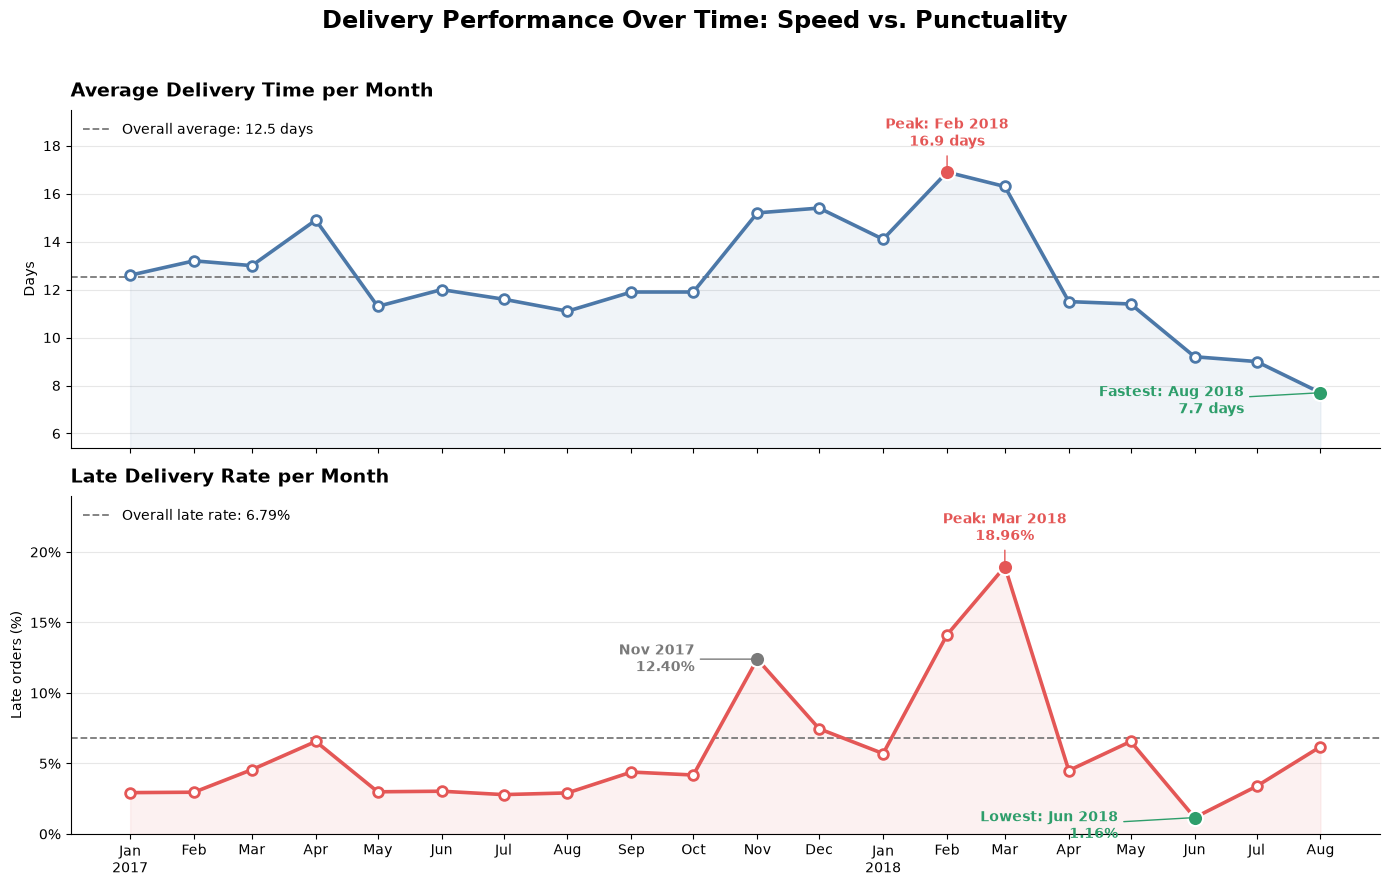

In [245]:
#Line charts: Monthly delivery duration and late delivery rate
df = delivery_monthly.copy()   

# Overall reference values (weighted by orders, so big months count more)
avg_time = (df["avg_delivery_time_days"] * df["orders_count"]).sum() / df["orders_count"].sum()
avg_late = df["late_orders"].sum() / df["orders_count"].sum() * 100

BLUE, RED, GREEN, GRAY = "#4C78A8", "#E45756", "#2E9E6B", "#7A7A7A"

def style_panel(ax, series, color, title, ylabel, fmt, avg_value, avg_label):
    """Line + soft fill, average line, and padded y-range for one panel."""
    ax.plot(df.index, series, color=color, linewidth=2.6, marker="o",
            markersize=7, markerfacecolor="white", markeredgewidth=2, zorder=3)
    ax.fill_between(df.index, series, series.min() * 0.0, color=color, alpha=0.08, zorder=1)
    ax.axhline(avg_value, color=GRAY, linestyle="--", linewidth=1.3, label=avg_label, zorder=2)

    lo, hi = series.min(), series.max()
    ax.set_ylim(max(0, lo - (hi - lo) * 0.25), hi + (hi - lo) * 0.28)   # headroom for labels
    ax.yaxis.set_major_formatter(plt.FuncFormatter(fmt))
    ax.set_title(title, fontsize=14, fontweight="bold", loc="left", pad=10)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper left", frameon=False, fontsize=10)

def callout(ax, when, value, text, color, dx, dy, ha="center"):
    """Highlighted point with a label that stays inside the plot."""
    ax.scatter(when, value, s=120, color=color, edgecolor="white", linewidth=1.5, zorder=5)
    ax.annotate(
        text, xy=(when, value), xytext=(dx, dy), textcoords="offset points",
        ha=ha, va="center", fontsize=10, fontweight="bold", color=color,
        arrowprops=dict(arrowstyle="-", color=color, linewidth=1),
        zorder=6,
    )

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# ---------- Top: average delivery time ----------
t = df["avg_delivery_time_days"]
style_panel(ax1, t, BLUE, "Average Delivery Time per Month", "Days",
            lambda v, _: f"{v:.0f}", avg_time, f"Overall average: {avg_time:.1f} days")

t_max, t_min = t.idxmax(), t.idxmin()
callout(ax1, t_max, t.max(), f"Peak: {t_max:%b %Y}\n{t.max():.1f} days", RED, 0, 28)
callout(ax1, t_min, t.min(), f"Fastest: {t_min:%b %Y}\n{t.min():.1f} days", GREEN, -55, -6, ha="right")

# ---------- Bottom: late delivery rate ----------
r = df["late_rate_pct"]
style_panel(ax2, r, RED, "Late Delivery Rate per Month", "Late orders (%)",
            lambda v, _: f"{v:.0f}%", avg_late, f"Overall late rate: {avg_late:.2f}%")

r_max, r_min = r.idxmax(), r.idxmin()
callout(ax2, r_max, r.max(), f"Peak: {r_max:%b %Y}\n{r.max():.2f}%", RED, 0, 28)
callout(ax2, r_min, r.min(), f"Lowest: {r_min:%b %Y}\n{r.min():.2f}%", GREEN, -55, -6, ha="right")

# Extra callout for the first spike (Nov 2017)
nov = df.index[df.index == "2017-11-01"]
if len(nov):
    callout(ax2, nov[0], r.loc[nov[0]], f"Nov 2017\n{r.loc[nov[0]]:.2f}%", GRAY, -45, 0, ha="right")

# ---------- Shared x-axis: every month, year shown under January ----------
ax2.set_xticks(df.index)
ax2.set_xticklabels(
    [f"{d:%b}\n{d.year}" if (d.month == 1 or i == 0) else f"{d:%b}" for i, d in enumerate(df.index)]
)
ax2.tick_params(axis="x", rotation=0)
ax2.set_xlabel("")

fig.suptitle("Delivery Performance Over Time: Speed vs. Punctuality",
             fontsize=17, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

#### Business Conclusion

The monthly delivery analysis reveals significant fluctuations in Olist's delivery performance between January 2017 and August 2018.

Two major periods of poor performance can be identified. The first occurred in November 2017, when the average delivery time increased to 15.2 days and the late delivery rate reached 12.40%. The situation became more critical in February and March 2018. March recorded the highest late delivery rate of the entire period (18.96%), while February had the longest average delivery time (16.9 days).

However, delivery performance improved considerably from April 2018 onward. Average delivery time declined to 7.7 days by August 2018, while the late delivery rate reached its lowest point of 1.16% in June 2018.

These findings suggest that Olist experienced substantial improvements in its delivery operations during the final months of the observed period. Nevertheless, the simultaneous deterioration of delivery speed and punctuality in late 2017 and early 2018 indicates that certain periods may have placed considerable pressure on the logistics system.

**Business Recommendations:**

- Investigate the operational factors behind the delivery deterioration in November 2017 and February–March 2018.
- Examine whether increased order volumes contributed to logistics capacity constraints during peak periods.
- Identify the operational practices associated with the improvements observed from April 2018 onward and consider applying them more broadly.
- Continue monitoring both average delivery time and late delivery rate, as improvements in delivery speed do not necessarily guarantee punctual deliveries.

**Overall Conclusion**

Olist experienced significant delivery performance challenges during late 2017 and early 2018, with February and March 2018 representing the most problematic period. However, the substantial improvement observed from April 2018 onward indicates a positive change in delivery operations.

Maintaining these improvements while ensuring consistent performance during periods of high demand should be a key operational priority. The company should focus not only on reducing delivery times but also on ensuring that orders consistently arrive within the promised delivery dates.

## Summary Report

### Objective
Evaluate Olist's delivery performance on delivered orders: how fast orders arrive, how often they meet the estimated delivery date, how severe the late deliveries are, how performance differs across Brazilian states, and how it changed from January 2017 to August 2018.

### Key Metrics

| Metric | Result |
|---|---|
| Delivered orders analysed | 96,470 |
| Average / median delivery time | 12.6 / 10.2 days |
| Middle 50% of orders (IQR) | 6.8 to 15.7 days |
| 90th percentile delivery time | 23.1 days |
| Longest delivery | 209.6 days |
| Delivered early | 88,644 orders (91.89%) |
| Delivered exactly on the estimated date | 1,292 orders (1.34%) |
| Delivered late | 6,534 orders (6.77%) |
| Late orders delayed by more than 7 days | 2,862 (43.80% of late orders, 2.97% of all orders) |
| Average / median delay of late orders | 10.6 / 7 days |
| States with both above-average delivery time and late rate | 16 of 27 |
| Worst month for late rate | March 2018 (18.96%) |
| Best month for late rate | June 2018 (1.16%) |

### Key Findings

1. **Typical delivery is reasonable, but the tail is long.** The mean (12.6 days) is above the median (10.2 days) and the standard deviation is 9.5 days. A small group of very slow orders pulls the average up, and 10% of orders take longer than 23 days. For setting customer expectations, the 90th percentile (23.1 days) is more useful than the average.

2. **Most orders beat their estimate, but late orders are often very late.** 91.89% of orders arrive before the estimated date, yet 6.77% arrive late, and the typical late order is a week late rather than a day or two. The 2,862 orders delayed by more than 7 days are the most damaging cases.

3. **The very high early-delivery share points to conservative estimates.** When more than 90% of orders arrive early and only 1.34% arrive exactly on the date, the estimates are probably padded. This protects the late rate but gives customers a less accurate promise.

4. **Delivery problems are regional.** The weighted national benchmarks are 12.57 days and a 6.77% late rate.
   - **Worst late rates:** AL (21.41%), MA (17.43%), SE (15.22%), PI (13.87%), CE (13.76%), BA (12.16%) and RJ (12.11%).
   - **Slowest states:** RR (29.4 days, but only 41 orders), AP (27.2 days) and AM (26.4 days).
   - **Benchmarks:** SP (8.8 days, 4.49% late), MG (12.0 days, 4.57%) and PR (12.0 days, 4.04%) combine fast delivery with a low late rate.
   - **Slow but predictable:** AP, AM, AC, RO and others deliver slowly but rarely miss the estimate (late rate under 4%). Their estimates seem to reflect the real transport time.

5. **Rates and absolute counts point to different priorities.** SP has a low late rate but 1,818 late orders, and RJ has 1,496. Together they account for about 51% of all late orders. AL has the worst rate but only about 85 late orders. Improving RJ would have the largest effect on the number of affected customers, while AL, MA, SE and CE need attention because the rate is so high.

6. **Performance deteriorated sharply twice, then recovered.**
   - **Late 2017:** November 2017 had a 12.40% late rate and 15.2 days average delivery time, with 7,288 orders (the highest volume to that point).
   - **Early 2018:** February and March 2018 were the worst months, with 16.9 days average delivery in February and a late rate of 14.13% in February and 18.96% in March (1,328 late orders in March).
   - **Not only volume:** January 2018 had almost the same volume as March (7,069 vs. 7,003 orders) but a late rate of only 5.70%. Higher volume alone does not explain the March problems.
   - **Recovery:** From April 2018 the late rate fell to 4.50% and average delivery time kept falling, to 7.7 days in August 2018.
   - **Speed vs. punctuality:** The late rate rose again in August 2018 (6.19%) even though delivery time was at its lowest. Fast delivery does not guarantee that the estimate is met.

## Business Conclusion

Olist's delivery performance is good on average but not consistently reliable. Most orders arrive early, but the average hides three weaknesses: a minority of orders arrive very late, performance differs strongly by region, and reliability fell sharply in two periods.

The goal should move from delivering earlier than estimated to delivering predictably. The 2018 recovery shows that much better performance is achievable, and SP, MG and PR show what good regional performance looks like.

### Recommendations

1. **Reduce severe delays.** Investigate the 2,862 orders delayed by more than 7 days (carrier, seller, route, product type) and set an alert for orders that risk passing the 7-day mark.
2. **Fix the highest-impact regions first.** Prioritize RJ and BA (high late rates with large volumes), then AL, MA, SE and CE (the highest late rates). Study SP, MG and PR to find practices that can be reused.
3. **Review the delivery estimates.** The share of early deliveries suggests padded estimates. Make them more accurate by state, and keep the longer estimates where they are working (AP, AM) so that promises stay realistic.
4. **Prepare for peak periods.** Find out what caused the problems in November 2017 and February-March 2018, and build capacity and carrier plans for high-demand periods before they start.
5. **Keep what worked in 2018.** Identify which changes drove the recovery from April 2018 and make them standard practice.
6. **Track speed and punctuality separately.** Report average delivery time, the 90th percentile, late rate and the share of orders delayed by more than 7 days, by state and by month.
